# ДЗ 1

Как запустить: python 3.11, `pip install -r requirements.txt`, данные сами скачаются первой ячейкой в разделе про данные в папку `data/`. Потом `jupyter nbconvert --to notebook --execute --inplace experiments.ipynb --ExecutePreprocessor.timeout=-1`. Сид и все настройки экспериментов в следующей ячейке. Полный прогон на cpu идет часа полтора-два.

In [1]:
import json
import os
import sys
import time
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch

sys.path.insert(0, os.getcwd())
from models import EASE, IALS, FactorizationMachine, ItemKNN, Popularity, TimeSVDpp
from recsys_utils.data import (META_URL, RATINGS_URL, TrainData, add_day_index, build_eval_set, clean_interactions,
                               download, encode_ids, load_meta, load_ratings, temporal_split)
from recsys_utils.evaluation import Evaluator
from recsys_utils.features import build_features
from recsys_utils.tuning import best_params, random_search

warnings.filterwarnings("ignore")
SEED = 67
np.random.seed(SEED)
torch.manual_seed(SEED)
K = 10
VAL_START, TEST_START = "2022-03-01", "2022-10-01"
T0 = pd.Timestamp("1999-01-01")
MIN_RELEVANT_RATING = 4.0
N_TRIALS = {"ItemKNN": 20, "iALS": 12, "EASE": 9, "FM": 8, "timeSVD++": 30}
IALS_ITER = 12
DATA_DIR, CACHE_DIR = "data", "cache"
os.makedirs(DATA_DIR, exist_ok=True)
os.makedirs(CACHE_DIR, exist_ok=True)
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 40)
pd.set_option("display.precision", 4)
pd.set_option("display.max_colwidth", None)
METRICS = ["ndcg@10", "recall@10", "precision@10", "coverage@10", "fit_time"]

## Данные

Amazon Reviews 2023 (McAuley Lab, UCSD), категория Video Games, версия 5-core rating-only плюс метаданные товаров. Источник https://amazon-reviews-2023.github.io/, прямые ссылки на файлы лежат в `recsys_utils/data.py`, качаются ячейкой ниже.

- `Video_Games.csv.gz`: `user_id`, `parent_asin` (id товара, варианты одного товара склеены в один), `rating` 1-5, `timestamp`. 5-core значит что у всех юзеров и товаров минимум 5 отзывов.
- `meta_Video_Games.jsonl.gz`: `title`, `main_category`, `categories` (путь по дереву категорий), `store` (бренд), `price` и тд. Поля `average_rating` и `rating_number` не используются, они посчитаны по всему датасету включая будущее, это лик.

Что рекомендуем: товары из Video Games, которые юзер еще не трогал. Отзыв это одновременно и факт интереса (неявный сигнал, на нем учатся ItemKNN, iALS, EASE, FM), и оценка (явный сигнал для timeSVD++). Попаданием считается товар, которому юзер потом поставил 4 или 5, тоесть не просто купил а остался доволен. Правило одно для всех моделей.

In [2]:
ratings_path = download(RATINGS_URL, f"{DATA_DIR}/Video_Games.csv.gz")
meta_path = download(META_URL, f"{DATA_DIR}/meta_Video_Games.jsonl.gz")
raw = load_ratings(ratings_path)
print(f"Исходно: {len(raw):,} взаимодействий, {raw.user_id.nunique():,} пользователей, {raw.item_id.nunique():,} товаров, "
      f"{raw.ts.min().date()} - {raw.ts.max().date()}")
raw.head()

Исходно: 814,586 взаимодействий, 94,762 пользователей, 25,612 товаров, 1999-10-22 - 2023-09-02


,user_id,item_id,rating,ts
0,AEVPPTMG43C6GWSR7I2UGRQN7WFQ,B08R5B7YS4,1.0,2021-01-24 03:41:06.223
1,AEVPPTMG43C6GWSR7I2UGRQN7WFQ,B0863MT183,4.0,2021-02-19 02:33:06.538
2,AEVPPTMG43C6GWSR7I2UGRQN7WFQ,B08P8P7686,5.0,2021-02-19 02:35:12.995
3,AEVPPTMG43C6GWSR7I2UGRQN7WFQ,B0B7LV3DN2,4.0,2021-04-05 16:50:45.475
4,AEVPPTMG43C6GWSR7I2UGRQN7WFQ,B09WMQ6DXG,5.0,2021-05-05 16:16:08.468


In [3]:
meta_cache = f"{CACHE_DIR}/item_meta_raw.parquet"
if os.path.exists(meta_cache):
    meta_raw = pd.read_parquet(meta_cache)
else:
    meta_raw = load_meta(meta_path, set(raw.item_id.unique()))
    meta_raw.to_parquet(meta_cache)
print(f"Товаров с метаданными: {meta_raw.item_id.nunique():,} из {raw.item_id.nunique():,}")
meta_raw.head()

Товаров с метаданными: 25,612 из 25,612


,item_id,title,main_category,categories,store,price,average_rating,rating_number,n_features,has_description,n_images,n_videos
0,B00Z9TLVK0,NBA 2K17 - Early Tip Off Edition - PlayStation 4,Video Games,"[Video Games, PlayStation 4, Games]",2K,58.00,4.3,223,10,True,10,1
1,B07H93H878,eXtremeRate Soft Touch Top Shell Front Housing Faceplate Replacement Parts with Side Rails Panel for Xbox One X & One S Controller (Shadow Purple),Video Games,"[Video Games, Xbox One, Accessories, Faceplates, Protectors & Skins]",eXtremeRate,17.59,4.5,3061,5,False,9,0
2,B00006969T,Konami Collector's Series: Castlevania & Contra - PC,Video Games,"[Video Games, PC, Games]",Square Enix,NaN,3.6,19,4,True,2,1
3,B07DL353F8,Tales of Vesperia - Definitive Edition - PlayStation 4,Video Games,"[Video Games, PlayStation 4, Games]",BANDAI NAMCO Entertainment,20.95,4.8,1389,4,True,7,1
4,B00BJH85SW,Turbo: Super Stunt Squad - Nintendo 3DS,Video Games,"[Video Games, Legacy Systems, Nintendo Systems, Nintendo 3DS & 2DS]",D3 Publisher,4.97,4.1,26,4,True,7,1


## Разбираемся с данными

### Чистка
Пропуски, оценки вне 1-5, дубли пар (юзер, товар); для дубля оставлялся бы последний по времени.

In [4]:
df, clean_stats = clean_interactions(raw)
print("Пропуски:", raw.isna().sum().to_dict())
pd.Series(clean_stats, name="строк").to_frame()

Пропуски: {'user_id': 0, 'item_id': 0, 'rating': 0, 'ts': 0}


,строк
исходно,814586
без пропусков,814586
"оценка в [1, 5]",814586
без дубликатов пар,814586


### Активность юзеров, популярность товаров, разреженость, время

Плотность матрицы: 0.03356%
На пользователя: медиана 6, среднее 8.6, макс 473; на товар: медиана 12, среднее 31.8, макс 2955


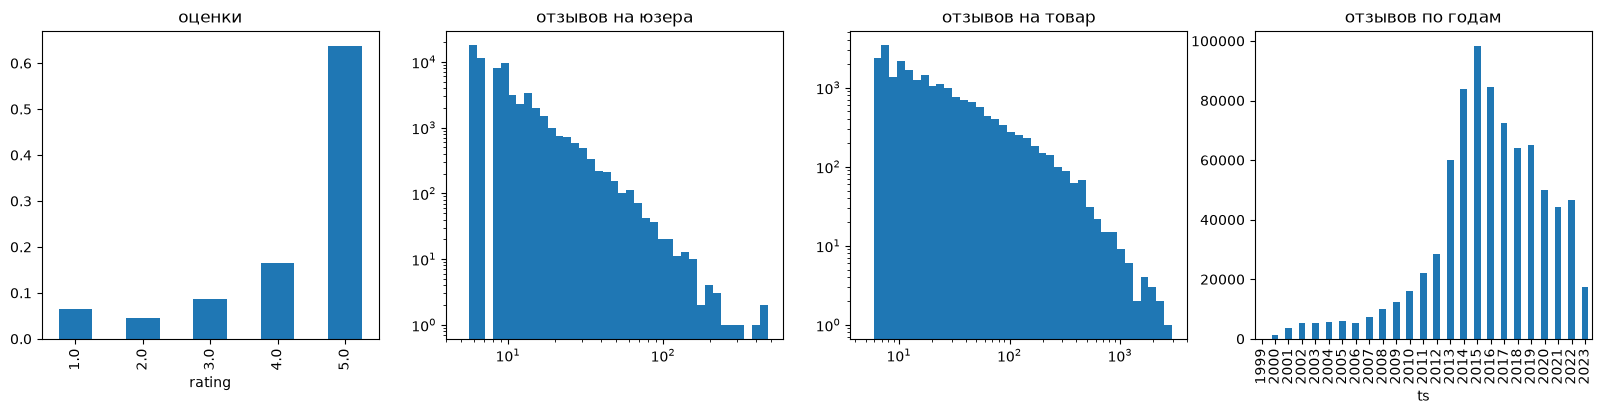

Последние месяцы: {Period('2023-01', 'M'): 5707, Period('2023-02', 'M'): 3753, Period('2023-03', 'M'): 4433, Period('2023-04', 'M'): 2388, Period('2023-05', 'M'): 618, Period('2023-06', 'M'): 212, Period('2023-07', 'M'): 156, Period('2023-08', 'M'): 103, Period('2023-09', 'M'): 1}


In [5]:
user_cnt, item_cnt = df.groupby("user_id").size(), df.groupby("item_id").size()
print(f"Плотность матрицы: {len(df) / (len(user_cnt) * len(item_cnt)):.5%}")
print(f"На пользователя: медиана {user_cnt.median():.0f}, среднее {user_cnt.mean():.1f}, макс {user_cnt.max()}; "
      f"на товар: медиана {item_cnt.median():.0f}, среднее {item_cnt.mean():.1f}, макс {item_cnt.max()}")
fig, ax = plt.subplots(1, 4, figsize=(20, 4))
df.rating.value_counts(normalize=True).sort_index().plot.bar(ax=ax[0], title="оценки")
ax[1].hist(user_cnt, bins=np.logspace(np.log10(5), np.log10(user_cnt.max()), 40)); ax[1].set(xscale="log", yscale="log", title="отзывов на юзера")
ax[2].hist(item_cnt, bins=np.logspace(np.log10(5), np.log10(item_cnt.max()), 40)); ax[2].set(xscale="log", yscale="log", title="отзывов на товар")
df.groupby(df.ts.dt.year).size().plot.bar(ax=ax[3], title="отзывов по годам")
plt.show()
by_month = df.groupby(df.ts.dt.to_period("M")).size()
print("Последние месяцы:", by_month[by_month.index >= pd.Period("2023-01", "M")].to_dict())

Основная масса отзывов 2013-2023, сбор данных обрывается в апреле 2023 (дальше хвостик около 1 тыс отзывов, он попадает в test и ни на что не влияет). Хвосты тяжелые: медианный юзер оставил 6 отзывов, медианный товар получил 12. 64% оценок это пятерки, тоесть явный сигнал сильно перекошен.

### Метаданные

title            1.000
main_category    0.980
categories       0.966
store            0.995
price            0.669
description      0.734
Узлов дерева категорий: 161 | медианная глубина пути: 4.0


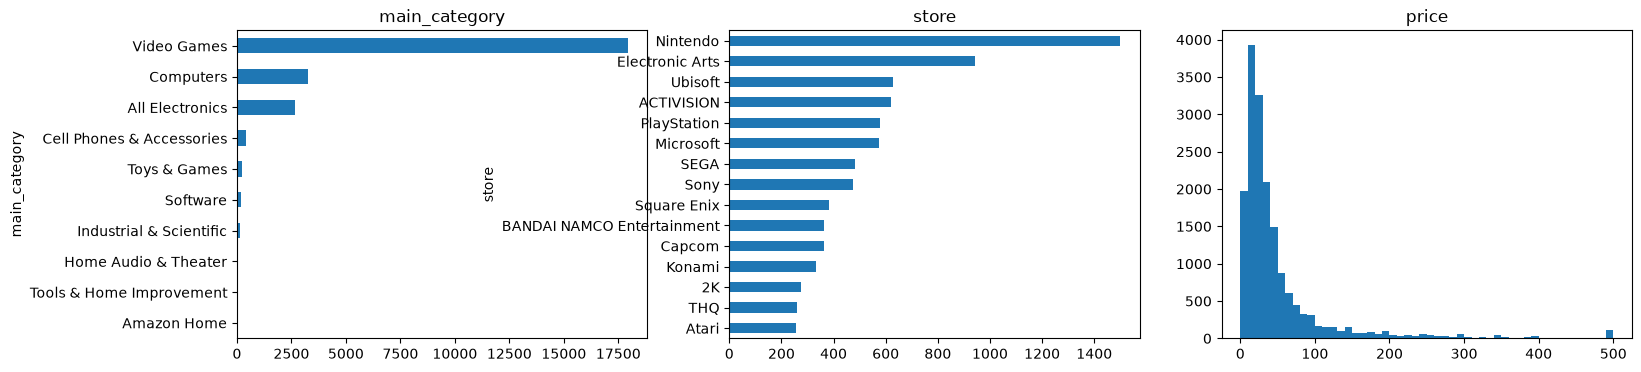

In [6]:
m = meta_raw.set_index("item_id").reindex(item_cnt.index)
cats = m.categories.apply(lambda x: list(x) if isinstance(x, (list, np.ndarray)) else [])
print(pd.Series({"title": m.title.notna().mean(), "main_category": m.main_category.notna().mean(), "categories": (cats.apply(len) > 0).mean(),
                 "store": m.store.notna().mean(), "price": m.price.notna().mean(), "description": m.has_description.mean()},
                name="доля товаров с полем").round(3).to_string())
print("Узлов дерева категорий:", len(set(c for cc in cats for c in cc)), "| медианная глубина пути:", cats.apply(len).median())
fig, ax = plt.subplots(1, 3, figsize=(18, 4))
m.main_category.value_counts().head(10).sort_values().plot.barh(ax=ax[0], title="main_category")
m.store.value_counts().head(15).sort_values().plot.barh(ax=ax[1], title="store")
ax[2].hist(m.price.dropna().clip(upper=500), bins=50); ax[2].set(title="price")
plt.show()

Название, категории и бренд есть почти у всех товаров, цена у двух третей. В FM пойдут категории, бренд и корзина по цене, плюс фичи которые считаются по train: популярность, возраст и средняя оценка товара, активность, средняя оценка, давность и профиль юзера по категориям и ценам.

### Фильтрация и подвыборка
5-core уже отфильтрован авторами (минимум 5 отзывов у юзера и товара). После чистки 814 586 взаимодействий, 94 762 юзера, 25 612 товаров, так как влезает в пределы дз, подвыборку не делал. Старые годы не выкидываются, они только в train и добавляют статистики по совместным покупкам.

In [7]:
df, users_index, items_index = encode_ids(df)
df = add_day_index(df, T0)
n_users, n_items = len(users_index), len(items_index)
meta = meta_raw.assign(item=items_index.get_indexer(meta_raw.item_id)).query("item >= 0").set_index("item").sort_index()
print(f"n_users = {n_users:,}, n_items = {n_items:,}")

n_users = 94,762, n_items = 25,612


## Как оцениваем

Делим по времени: train это все до 2022-03-01, validation с 2022-03-01 по 2022-10-01, test с 2022-10-01 до конца данных. Настройки подбираются на validation (обучение на train), для финала модели с выбранными настройками переучиваются на train + validation и один раз считаются на test. День, на который строятся рекомендации ($t_{rec}$), это начало окна оценки.

Оцениваются только юзеры, у которых есть история в обучающей части; новым показывали бы просто популярное. Рекомендовать можно только товары из обучающей части, отзывы на новые товары выкидываются (ни одна из моделей их все равно не порекомендует). Из выдачи убирается то, что юзер уже покупал (на test из train + validation). Попадание = оценка 4 или 5 в окне; юзеры без попаданий в окне не оцениваются.

Метрики при K = 10, среднее по юзерам. Главная NDCG@10, выбрана заранее до подбора: учитывает и сколько попали, и на каких позициях, нормально работает когда попаданий несколько. Вторая Recall@10, какую долю нужных товаров нашли (их 1-2 на юзера, так что это почти hit rate). Еще считаются Precision@10 и Coverage@10, это доля каталога, которую хоть кому-то показали.

In [8]:
train, val, test = temporal_split(df, VAL_START, TEST_START)
trainval = pd.concat([train, val], ignore_index=True)
pd.DataFrame({name: {"взаимодействий": len(p), "пользователей": p.user.nunique(), "товаров": p.item.nunique(), "с": p.ts.min().date(), "по": p.ts.max().date()}
              for name, p in [("train", train), ("validation", val), ("test", test)]}).T

,взаимодействий,пользователей,товаров,с,по
train,757766,92458,23660,1999-10-22,2022-02-28
validation,23060,10921,6166,2022-03-01,2022-09-30
test,33760,11125,6684,2022-10-01,2023-09-02


In [9]:
relevant_val, stats_val = build_eval_set(train, val, MIN_RELEVANT_RATING)
relevant_test, stats_test = build_eval_set(trainval, test, MIN_RELEVANT_RATING)
data_val = TrainData(train, n_users, n_items, (pd.Timestamp(VAL_START) - T0).days, meta)
data_test = TrainData(trainval, n_users, n_items, (pd.Timestamp(TEST_START) - T0).days, meta)
ev_val, ev_test = Evaluator(data_val, relevant_val, K), Evaluator(data_test, relevant_test, K)
pd.DataFrame({"validation": stats_val, "test": stats_test})

,validation,test
строк в окне,23060.000,33760.000
пользователей в окне,10921.000,11125.000
строк холодных пользователей,4271.000,10210.000
холодных пользователей,955.000,1349.000
строк с холодными товарами,3870.000,8196.000
тёплых строк,14919.000,15354.000
из них положительных,11304.000,11939.000
оцениваемых пользователей,6667.000,6546.000
релевантных на пользователя,1.696,1.824


## Модели и подбор настроек на validation

Случайный поиск с фиксированным сидом (первый вариант это центр сетки), критерий NDCG@10 на validation. Результаты кешируются в `cache/tuning_*.jsonl`.

### Бейзлайн: популярность
score(u, i) = сколько раз товар i встретился в train.

In [10]:
pop_val = ev_val.fit_and_evaluate(Popularity())
pd.Series(pop_val)[METRICS].to_frame("Popularity").T

,ndcg@10,recall@10,precision@10,coverage@10,fit_time
Popularity,0.0041,0.0067,0.0014,0.0008,1.9348


### ItemKNN

$X$ это матрица взаимодействий (бинарная или с оценками), $x_i$ столбец товара. Похожесть это косинус со сжатием и асимметрией:

$$\operatorname{sim}(i,j)=\frac{\langle x_i,x_j\rangle}{\|x_i\|^{2\alpha}\,\|x_j\|^{2(1-\alpha)}+\text{shrink}}$$

shrink прибивает пары, у которых мало общих юзеров, $\alpha=0.5$ это обычный косинус. У каждого товара остаются $k$ ближайших соседей $N(i)$, скор это сумма похожестей с историей юзера:

$$\operatorname{score}(u,i)=\sum_{j\in I_u\cap N(i)}\operatorname{sim}(i,j)\qquad(\text{normalize: деление на }\textstyle\sum_{j\in N(i)}|\operatorname{sim}(i,j)|)$$

Взят item-based вариант, потому что товаров в 4 раза меньше чем юзеров и статистика по товару надежнее (у медианного юзера всего 6 отзывов). В лекции похожесть товаров считали на оценках, центрированных по юзеру (adjusted cosine), но тут матрица бинарная (был отзыв или нет), центрировать нечего, поэтому обычный косинус со сжатием; вариант с весами-оценками тоже в сетке. Все на разреженных матрицах.

Сетка: $k\in\{20,50,100,200,400\}$, shrink $\in\{0,5,10,25,50,100\}$, $\alpha\in\{0.3,0.4,0.5,0.6,0.7\}$, веса бинарные или оценки, нормировка да или нет.

In [11]:
space_knn = {"k_neighbors": [100, 20, 50, 200, 400], "shrink": [10, 0, 5, 25, 50, 100], "alpha": [0.5, 0.3, 0.4, 0.6, 0.7],
             "weighting": ["binary", "rating"], "normalize": [False, True]}
res_knn = random_search(ItemKNN, space_knn, ev_val, N_TRIALS["ItemKNN"], seed=SEED, cache_path=f"{CACHE_DIR}/tuning_itemknn.jsonl")
best_knn = best_params(res_knn)
print(best_knn)
res_knn.head()

[ItemKNN 1/20] ndcg@10=0.0100 fit=1s {'k_neighbors': 100, 'shrink': 10, 'alpha': 0.5, 'weighting': 'binary', 'normalize': False}
[ItemKNN 2/20] ndcg@10=0.0099 fit=2s {'k_neighbors': 200, 'shrink': 5, 'alpha': 0.4, 'weighting': 'binary', 'normalize': False}
[ItemKNN 3/20] ndcg@10=0.0042 fit=2s {'k_neighbors': 50, 'shrink': 25, 'alpha': 0.3, 'weighting': 'rating', 'normalize': True}
[ItemKNN 4/20] ndcg@10=0.0075 fit=2s {'k_neighbors': 200, 'shrink': 5, 'alpha': 0.7, 'weighting': 'binary', 'normalize': False}
[ItemKNN 5/20] ndcg@10=0.0080 fit=2s {'k_neighbors': 20, 'shrink': 5, 'alpha': 0.5, 'weighting': 'binary', 'normalize': True}
[ItemKNN 6/20] ndcg@10=0.0047 fit=2s {'k_neighbors': 50, 'shrink': 0, 'alpha': 0.3, 'weighting': 'binary', 'normalize': True}
[ItemKNN 7/20] ndcg@10=0.0034 fit=3s {'k_neighbors': 400, 'shrink': 50, 'alpha': 0.7, 'weighting': 'rating', 'normalize': True}
[ItemKNN 8/20] ndcg@10=0.0064 fit=2s {'k_neighbors': 50, 'shrink': 50, 'alpha': 0.4, 'weighting': 'binary', 

,param_k_neighbors,param_shrink,param_alpha,param_weighting,param_normalize,ndcg@10,recall@10,precision@10,coverage@10,fit_time
0,20,50,0.3,binary,False,0.0107,0.0176,0.0033,0.4304,2.2445
1,20,50,0.6,binary,False,0.0102,0.0171,0.0032,0.4579,2.3231
2,100,10,0.5,binary,False,0.0100,0.0165,0.0031,0.5877,0.7163
3,200,5,0.4,binary,False,0.0099,0.0159,0.0030,0.6186,2.2110
4,20,0,0.6,rating,True,0.0088,0.0155,0.0028,0.5841,2.2335


### iALS

$r_{ui}=1$ если отзыв был. Предпочтение $p_{ui}=\mathbb 1[r_{ui}>0]$, уверенность $c_{ui}=1+\alpha r_{ui}$, сумма по всем парам (нули тоже, с уверенностью 1):

$$L=\sum_{u,i}c_{ui}(p_{ui}-x_u^\top y_i)^2+\lambda\Big(\sum_u\|x_u\|^2+\sum_i\|y_i\|^2\Big),\qquad
x_u=\big(Y^\top Y+Y^\top(C^u-I)Y+\lambda I\big)^{-1}Y^\top C^u p_u$$

и так же для $y_i$. $Y^\top Y$ считается один раз за итерацию, а в $Y^\top(C^u-I)Y=\sum_{i\in I_u}(c_{ui}-1)y_iy_i^\top$ всего $|I_u|$ слагаемых, поэтому все линейно по числу взаимодействий. Юзеры с одинаковым $|I_u|$ решаются батчем. Скор $x_u^\top y_i$.

Сетка: $f\in\{32,64,128\}$, $\lambda\in[0.01,10]$, $\alpha\in[1,300]$ (лог шкала), 12 итераций.

In [12]:
space_ials = {"factors": [64, 32, 128], "reg": ("loguniform", 0.01, 10.0), "alpha": ("loguniform", 1.0, 300.0)}
res_ials = random_search(IALS, space_ials, ev_val, N_TRIALS["iALS"], seed=SEED, fixed={"iterations": IALS_ITER, "seed": SEED},
                         cache_path=f"{CACHE_DIR}/tuning_ials.jsonl")
best_ials = best_params(res_ials)
print(best_ials)
res_ials.head()

[iALS 1/12] ndcg@10=0.0103 fit=17s {'factors': 64, 'reg': 0.316, 'alpha': 17.3}
[iALS 2/12] ndcg@10=0.0116 fit=57s {'factors': 128, 'reg': 0.024, 'alpha': 18.8}
[iALS 3/12] ndcg@10=0.0105 fit=7s {'factors': 32, 'reg': 0.0779, 'alpha': 30.3}
[iALS 4/12] ndcg@10=0.0105 fit=56s {'factors': 128, 'reg': 0.0841, 'alpha': 7.59}
[iALS 5/12] ndcg@10=0.0105 fit=8s {'factors': 32, 'reg': 0.0184, 'alpha': 182.0}
[iALS 6/12] ndcg@10=0.0110 fit=7s {'factors': 32, 'reg': 0.0109, 'alpha': 106.0}
[iALS 7/12] ndcg@10=0.0098 fit=16s {'factors': 64, 'reg': 3.63, 'alpha': 251.0}
[iALS 8/12] ndcg@10=0.0100 fit=7s {'factors': 32, 'reg': 0.104, 'alpha': 8.6}
[iALS 9/12] ndcg@10=0.0102 fit=56s {'factors': 128, 'reg': 0.0483, 'alpha': 6.8}
[iALS 10/12] ndcg@10=0.0096 fit=8s {'factors': 32, 'reg': 0.0726, 'alpha': 5.69}
[iALS 11/12] ndcg@10=0.0088 fit=53s {'factors': 128, 'reg': 0.808, 'alpha': 2.67}
[iALS 12/12] ndcg@10=0.0085 fit=52s {'factors': 128, 'reg': 2.55, 'alpha': 1.8}
{'factors': 128.0, 'reg': 0.024, 

,param_factors,param_reg,param_alpha,ndcg@10,recall@10,precision@10,coverage@10,fit_time
0,128,0.0240,18.80,0.0116,0.0194,0.0035,0.0970,56.6681
1,32,0.0109,106.00,0.0110,0.0194,0.0034,0.0755,7.0820
2,32,0.0779,30.30,0.0105,0.0176,0.0032,0.0477,7.3144
3,32,0.0184,182.00,0.0105,0.0187,0.0033,0.0913,7.5674
4,128,0.0841,7.59,0.0105,0.0173,0.0033,0.0743,55.5663


### EASE

Матрица весов товар-товар $B$ с нулями на диагонали, которая восстанавливает $X$ из самой себя:

$$\min_B\|X-XB\|_F^2+\lambda\|B\|_F^2,\ \operatorname{diag}B=0\quad\Rightarrow\quad P=(X^\top X+\lambda I)^{-1},\ B_{ij}=-\frac{P_{ij}}{P_{jj}}\ (i\ne j),\ B_{jj}=0$$

Обучение это одно обращение матрицы $25\,612^2$ (float32, где-то минута). Скор $x_uB$. Взят вместо SLIM: та же идея, но считается одной формулой вместо покоординатного спуска с L1 (готовый ElasticNet нельзя, а свой на 25 тыс столбцов считался бы вечность).

Сетка: $\lambda\in\{10,20,50,100,200,500,1000,2000,5000\}$.

In [13]:
space_ease = {"reg": [500.0, 50.0, 100.0, 200.0, 1000.0, 2000.0, 5000.0, 10.0, 20.0]}
res_ease = random_search(EASE, space_ease, ev_val, N_TRIALS["EASE"], seed=SEED, cache_path=f"{CACHE_DIR}/tuning_ease.jsonl")
best_ease = best_params(res_ease)
print(best_ease)
res_ease.sort_values("param_reg")[["param_reg"] + METRICS]

[EASE 1/9] ndcg@10=0.0111 fit=63s {'reg': 500.0}
[EASE 2/9] ndcg@10=0.0117 fit=76s {'reg': 10.0}
[EASE 3/9] ndcg@10=0.0117 fit=62s {'reg': 200.0}
[EASE 4/9] ndcg@10=0.0107 fit=63s {'reg': 2000.0}
[EASE 5/9] ndcg@10=0.0123 fit=60s {'reg': 50.0}
[EASE 6/9] ndcg@10=0.0107 fit=63s {'reg': 1000.0}
[EASE 7/9] ndcg@10=0.0123 fit=61s {'reg': 100.0}
[EASE 8/9] ndcg@10=0.0102 fit=60s {'reg': 5000.0}
[EASE 9/9] ndcg@10=0.0123 fit=77s {'reg': 20.0}
{'reg': 20.0}


,param_reg,ndcg@10,recall@10,precision@10,coverage@10,fit_time
4,10.0,0.0117,0.0195,0.0036,0.3951,75.6955
0,20.0,0.0123,0.0198,0.0037,0.3412,76.8082
1,50.0,0.0123,0.0200,0.0037,0.2911,60.1793
2,100.0,0.0123,0.0206,0.0038,0.2671,60.8325
3,200.0,0.0117,0.0202,0.0037,0.2516,61.9703
5,500.0,0.0111,0.0193,0.0036,0.2385,63.3516
6,1000.0,0.0107,0.0184,0.0035,0.2322,63.2745
7,2000.0,0.0107,0.0186,0.0036,0.2258,62.8199
8,5000.0,0.0102,0.0175,0.0035,0.2208,60.2825


### FM с доп признаками

Пара (u, i) это разреженный вектор $x=x_u\oplus x_i$:

$$\hat y(x)=w_0+\sum_f w_fx_f+\sum_{f<g}\langle v_f,v_g\rangle x_fx_g,\qquad
\sum_{f<g}\langle v_f,v_g\rangle x_fx_g=\tfrac12\sum_{d=1}^k\Big[\Big(\sum_f v_{fd}x_f\Big)^2-\sum_f v_{fd}^2x_f^2\Big]$$

Пользовательская часть вектора одинакова для всех товаров, поэтому скоры по всему каталогу считаются одним матричным умножением.

Фичи (`recsys_utils/features.py`, все известны на момент $t_{rec}$). Товар: id, main_category, узлы пути categories (multi-hot с весом $1/n$), store, корзина по цене, корзины по популярности, возрасту (дней с первого отзыва в train) и средней оценке по train. Юзер: id, корзины по активности, средней оценке и давности последнего отзыва по train, профиль по категориям купленного (нормированный multi-hot), корзина по средней цене купленного. Зачем: категории, бренд и цена помогают с редкими товарами и юзерами с 1-3 покупками, у которых по одним id почти ничего не выучить, а фичи по train дают популярность и свежесть товара.

Учится на парах лоссом BPR, негативы берутся равномерно из каталога (не из истории юзера), Adam, autograd, регуляризуются только параметры из батча:
$L=-\sum_{(u,i,j)}\ln\sigma(\hat y(u,i)-\hat y(u,j))+\lambda\|\Theta_{batch}\|^2$

Сетка: $k\in\{16,32,64\}$, lr $\in[10^{-3},2\cdot10^{-2}]$, $\lambda\in[10^{-4},10^{-1}]$, эпох $\{10,20\}$, негативов на позитив $\{1,3\}$.

In [14]:
build_features(data_val).describe()

,user_id,user_activity_bin,user_mean_rating_bin,user_recency_bin,item_id,item_main_category,item_category_token,item_store,item_price_bin,item_pop_bin,item_mean_rating_bin,item_age_bin,user_category_profile,user_price_bin
size,94762,8,6,7,25612,20,91,318,9,9,6,8,91,9


In [15]:
space_fm = {"factors": [32, 16, 64], "lr": ("loguniform", 1e-3, 2e-2), "reg": ("loguniform", 1e-4, 1e-1), "epochs": [10, 20], "n_neg": [1, 3]}
res_fm = random_search(FactorizationMachine, space_fm, ev_val, N_TRIALS["FM"], seed=SEED, fixed={"seed": SEED, "batch_size": 4096},
                       cache_path=f"{CACHE_DIR}/tuning_fm.jsonl")
best_fm = best_params(res_fm)
print(best_fm)
res_fm.head()

[FM 1/8] ndcg@10=0.0090 fit=171s {'factors': 32, 'lr': 0.00447, 'reg': 0.00316, 'epochs': 10, 'n_neg': 1}
[FM 2/8] ndcg@10=0.0097 fit=313s {'factors': 64, 'lr': 0.00146, 'reg': 0.00348, 'epochs': 10, 'n_neg': 3}
[FM 3/8] ndcg@10=0.0085 fit=372s {'factors': 32, 'lr': 0.006, 'reg': 0.00197, 'epochs': 20, 'n_neg': 1}
[FM 4/8] ndcg@10=0.0077 fit=338s {'factors': 32, 'lr': 0.0013, 'reg': 0.0545, 'epochs': 10, 'n_neg': 3}
[FM 5/8] ndcg@10=0.0078 fit=691s {'factors': 32, 'lr': 0.00104, 'reg': 0.0283, 'epochs': 20, 'n_neg': 3}
[FM 6/8] ndcg@10=0.0073 fit=733s {'factors': 64, 'lr': 0.00861, 'reg': 0.00104, 'epochs': 20, 'n_neg': 3}
[FM 7/8] ndcg@10=0.0102 fit=285s {'factors': 16, 'lr': 0.00198, 'reg': 0.00102, 'epochs': 10, 'n_neg': 3}
[FM 8/8] ndcg@10=0.0085 fit=248s {'factors': 64, 'lr': 0.00249, 'reg': 0.00808, 'epochs': 10, 'n_neg': 1}
{'factors': 16.0, 'lr': 0.00198, 'reg': 0.00102, 'epochs': 10.0, 'n_neg': 3.0}


,param_factors,param_lr,param_reg,param_epochs,param_n_neg,ndcg@10,recall@10,precision@10,coverage@10,fit_time
0,16,0.0020,0.0010,10,3,0.0102,0.0183,0.0033,0.0659,285.4274
1,64,0.0015,0.0035,10,3,0.0097,0.0178,0.0031,0.0686,312.8499
2,32,0.0045,0.0032,10,1,0.0090,0.0157,0.0028,0.0843,171.1338
3,64,0.0025,0.0081,10,1,0.0085,0.0144,0.0026,0.0579,248.3081
4,32,0.0060,0.0020,20,1,0.0085,0.0160,0.0026,0.1413,372.0971


### timeSVD++

Явный сигнал: оценка $r_{ui}$ в день $t$. База это SVD++: $\hat r_{ui}=\mu+b_u+b_i+q_i^\top\big(p_u+|N(u)|^{-1/2}\sum_{j\in N(u)}y_j\big)$, где $N(u)$ история юзера. Временные компоненты:

$$b_i(t)=b_i+b_{i,\mathrm{Bin}(t)},\qquad b_u(t)=b_u+\alpha_u\,\mathrm{dev}_u(t)+b_{u,t},\qquad \mathrm{dev}_u(t)=\operatorname{sign}(t-t_u)|t-t_u|^{\beta}/D,$$
$$\hat r_{ui}(t)=\mu+b_u(t)+b_i(t)+q_i^\top\Big(p_u+\alpha_u^{(k)}\mathrm{dev}_u(t)+|N(u)|^{-1/2}\sum_{j\in N(u)}y_j\Big)$$

$\mathrm{Bin}(t)$ это временная корзина (популярность товара плывет во времени), $t_u$ средняя дата оценок юзера, $\mathrm{dev}_u(t)$ насколько день $t$ раньше или позже его обычного времени, $b_{u,t}$ смещение конкретного дня. Дневные смещения $b_{u,t}$ и дрейф факторов $lpha_u^{(k)}$ включаются опционально. Учится SGD по MSE с L2 на затронутые параметры.

Рекомендации: считается $\hat r_{ui}(t_{rec})$, где $\mathrm{Bin}(t_{rec})$ это последняя корзина train, $b_{u,t_{rec}}=0$, дрейф продлевается вперед; top-10 по предсказанной оценке.

Сетка: $k\in\{32,64\}$, lr $\in[2\cdot10^{-3},2\cdot10^{-2}]$, $\lambda_{bias}\in[10^{-3},0.4]$, $\lambda_{factor}\in[5\cdot10^{-3},0.5]$, $\lambda_\alpha,\lambda_{day}\in\{0.1,1,10\}$, эпох $\{1,2,3,5,10,20\}$ (число эпох это по сути ранняя остановка по метрике ранжирования), $n_{bins}\in\{10,30\}$, дневные смещения и дрейф факторов вкл или выкл; 30 вариантов, одна эпоха считается секунды. Диапазоны по регуляризации сужены после пробного прогона: при $\lambda_{bias}$ около 1 и больше смещения товаров уезжают в ноль и модель вырождается почти в константу.

In [16]:
space_tsvd = {"factors": [32, 64], "lr": ("loguniform", 2e-3, 2e-2), "reg_bias": ("loguniform", 1e-3, 0.4), "reg_factor": ("loguniform", 5e-3, 0.5),
              "reg_alpha": [0.1, 1.0, 10.0], "reg_day": [1.0, 0.1, 10.0], "epochs": [1, 2, 3, 5, 10, 20], "n_bins": [30, 10],
              "day_bias": [True, False], "factor_drift": [False, True]}
res_tsvd = random_search(TimeSVDpp, space_tsvd, ev_val, N_TRIALS["timeSVD++"], seed=SEED, fixed={"seed": SEED},
                         cache_path=f"{CACHE_DIR}/tuning_timesvdpp.jsonl")
best_tsvd = best_params(res_tsvd)
print(best_tsvd)
res_tsvd.head()

[timeSVD++ 1/30] ndcg@10=0.0059 fit=7s {'factors': 32, 'lr': 0.00632, 'reg_bias': 0.02, 'reg_factor': 0.05, 'reg_alpha': 0.1, 'reg_day': 1.0, 'epochs': 1, 'n_bins': 30, 'day_bias': True, 'factor_drift': False}
[timeSVD++ 2/30] ndcg@10=0.0035 fit=43s {'factors': 64, 'lr': 0.00268, 'reg_bias': 0.0217, 'reg_factor': 0.0197, 'reg_alpha': 1.0, 'reg_day': 10.0, 'epochs': 5, 'n_bins': 10, 'day_bias': True, 'factor_drift': True}
[timeSVD++ 3/30] ndcg@10=0.0051 fit=21s {'factors': 32, 'lr': 0.00453, 'reg_bias': 0.0017, 'reg_factor': 0.334, 'reg_alpha': 1.0, 'reg_day': 1.0, 'epochs': 3, 'n_bins': 30, 'day_bias': False, 'factor_drift': True}
[timeSVD++ 4/30] ndcg@10=0.0015 fit=22s {'factors': 64, 'lr': 0.0186, 'reg_bias': 0.0742, 'reg_factor': 0.0238, 'reg_alpha': 10.0, 'reg_day': 10.0, 'epochs': 3, 'n_bins': 10, 'day_bias': True, 'factor_drift': False}
[timeSVD++ 5/30] ndcg@10=0.0034 fit=20s {'factors': 32, 'lr': 0.0102, 'reg_bias': 0.00558, 'reg_factor': 0.0204, 'reg_alpha': 10.0, 'reg_day': 0.

,param_factors,param_lr,param_reg_bias,param_reg_factor,param_reg_alpha,param_reg_day,param_epochs,param_n_bins,param_day_bias,param_factor_drift,ndcg@10,recall@10,precision@10,coverage@10,fit_time
0,64,0.0021,0.0027,0.0083,1.0,0.1,2,30,False,True,0.0106,0.0170,0.0033,0.0006,16.2359
1,32,0.0025,0.0232,0.2830,0.1,0.1,1,10,True,True,0.0104,0.0163,0.0032,0.0008,8.2396
2,64,0.0029,0.0859,0.0052,1.0,1.0,1,10,False,False,0.0103,0.0165,0.0033,0.0007,8.1135
3,32,0.0031,0.0111,0.0281,1.0,10.0,1,10,True,True,0.0102,0.0163,0.0032,0.0007,7.6851
4,32,0.0025,0.0018,0.0628,10.0,1.0,2,10,False,True,0.0091,0.0106,0.0024,0.0007,13.7016


### Сводка по validation

In [17]:
summary_val = pd.DataFrame({"Popularity": pop_val, "ItemKNN": res_knn.iloc[0], "iALS": res_ials.iloc[0], "EASE": res_ease.iloc[0],
                            "FM": res_fm.iloc[0], "timeSVD++": res_tsvd.iloc[0]}).T[METRICS].astype(float)
summary_val.sort_values("ndcg@10", ascending=False)

,ndcg@10,recall@10,precision@10,coverage@10,fit_time
EASE,0.0123,0.0198,0.0037,0.3412,76.8082
iALS,0.0116,0.0194,0.0035,0.0970,56.6681
ItemKNN,0.0107,0.0176,0.0033,0.4304,2.2445
timeSVD++,0.0106,0.0170,0.0033,0.0006,16.2359
FM,0.0102,0.0183,0.0033,0.0659,285.4274
Popularity,0.0041,0.0067,0.0014,0.0008,1.9348


## Сравнение на test

Модели с выбранными настройками переучиваются на train + validation и считаются на test по тем же правилам. Плюс две проверки: FM только на id и SVD++ без времени, чтобы увидеть, что дают доп признаки и время.

In [18]:
specs = {
    "Popularity": (Popularity, {}),
    "ItemKNN": (ItemKNN, best_knn),
    "iALS": (IALS, {"iterations": IALS_ITER, "seed": SEED, **best_ials}),
    "EASE": (EASE, best_ease),
    "FM": (FactorizationMachine, {"seed": SEED, "batch_size": 4096, **best_fm}),
    "timeSVD++": (TimeSVDpp, {"seed": SEED, **best_tsvd}),
    "FM (только id)": (FactorizationMachine, {"seed": SEED, "batch_size": 4096, "use_item_meta": False, "use_user_meta": False, **best_fm}),
    "SVD++ (без времени)": (TimeSVDpp, {"seed": SEED, "use_time": False, **best_tsvd}),
}
results = {}
for name, (cls, params) in specs.items():
    results[name] = {**ev_test.fit_and_evaluate(cls(**params)), "гиперпараметры": json.dumps(params) if params else "-"}
    print(f"{name:20s} " + " ".join(f"{m}={results[name][m]:.4f}" for m in METRICS[:-1]))
final = pd.DataFrame(results).T
final[METRICS] = final[METRICS].astype(float)
final.iloc[:6].sort_values("ndcg@10", ascending=False)

Popularity           ndcg@10=0.0033 recall@10=0.0055 precision@10=0.0012 coverage@10=0.0007


ItemKNN              ndcg@10=0.0101 recall@10=0.0167 precision@10=0.0033 coverage@10=0.4300


iALS                 ndcg@10=0.0124 recall@10=0.0204 precision@10=0.0040 coverage@10=0.0961


EASE                 ndcg@10=0.0118 recall@10=0.0187 precision@10=0.0038 coverage@10=0.3505


FM                   ndcg@10=0.0108 recall@10=0.0189 precision@10=0.0034 coverage@10=0.0740


timeSVD++            ndcg@10=0.0101 recall@10=0.0143 precision@10=0.0026 coverage@10=0.0006


FM (только id)       ndcg@10=0.0034 recall@10=0.0058 precision@10=0.0013 coverage@10=0.0089


SVD++ (без времени)  ndcg@10=0.0098 recall@10=0.0145 precision@10=0.0027 coverage@10=0.0007


,ndcg@10,recall@10,precision@10,coverage@10,fit_time,гиперпараметры
iALS,0.0124,0.0204,0.0040,0.0961,57.4291,"{""iterations"": 12, ""seed"": 67, ""factors"": 128.0, ""reg"": 0.024, ""alpha"": 18.8}"
EASE,0.0118,0.0187,0.0038,0.3505,73.0191,"{""reg"": 20.0}"
FM,0.0108,0.0189,0.0034,0.0740,254.5813,"{""seed"": 67, ""batch_size"": 4096, ""factors"": 16.0, ""lr"": 0.00198, ""reg"": 0.00102, ""epochs"": 10.0, ""n_neg"": 3.0}"
timeSVD++,0.0101,0.0143,0.0026,0.0006,18.1724,"{""seed"": 67, ""factors"": 64, ""lr"": 0.00205, ""reg_bias"": 0.00265, ""reg_factor"": 0.00835, ""reg_alpha"": 1.0, ""reg_day"": 0.1, ""epochs"": 2, ""n_bins"": 30, ""day_bias"": false, ""factor_drift"": true}"
ItemKNN,0.0101,0.0167,0.0033,0.4300,2.2412,"{""k_neighbors"": 20, ""shrink"": 50, ""alpha"": 0.3, ""weighting"": ""binary"", ""normalize"": false}"
Popularity,0.0033,0.0055,0.0012,0.0007,1.5305,-


In [19]:
final.loc[["FM", "FM (только id)", "timeSVD++", "SVD++ (без времени)"], METRICS]

,ndcg@10,recall@10,precision@10,coverage@10,fit_time
FM,0.0108,0.0189,0.0034,0.0740,254.5813
FM (только id),0.0034,0.0058,0.0013,0.0089,69.0247
timeSVD++,0.0101,0.0143,0.0026,0.0006,18.1724
SVD++ (без времени),0.0098,0.0145,0.0027,0.0007,13.6894


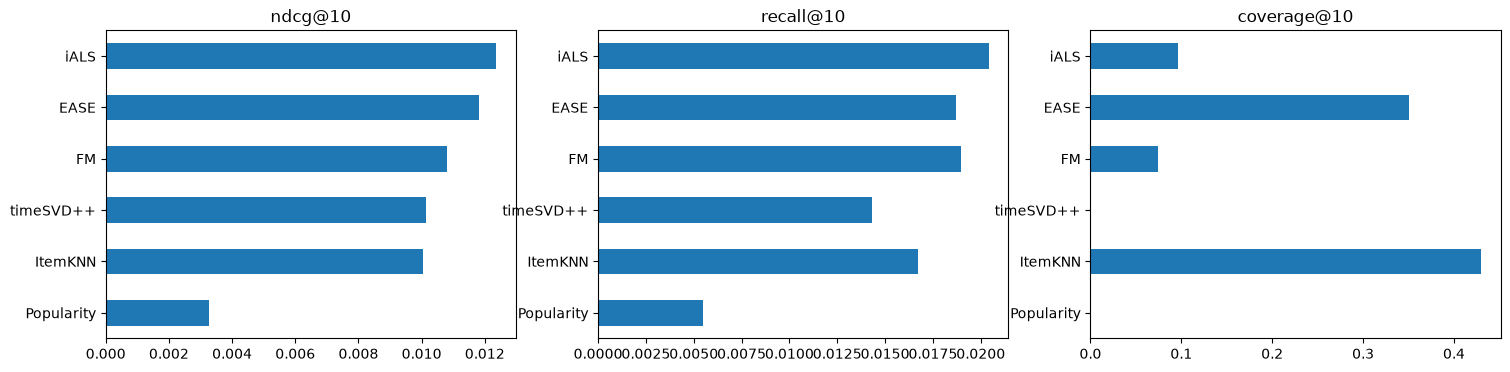

In [20]:
fig, ax = plt.subplots(1, 3, figsize=(18, 4))
order = final.iloc[:6].sort_values("ndcg@10").index
for a, metric in zip(ax, ["ndcg@10", "recall@10", "coverage@10"]):
    final.loc[order, metric].plot.barh(ax=a, title=metric)
plt.show()

## Выводы

На test по NDCG@10: iALS 0.0124, EASE 0.0118, FM 0.0108, ItemKNN 0.0101, timeSVD++ 0.0101, популярность 0.0033 (Recall@10 соответственно 0.0204, 0.0187, 0.0189, 0.0167, 0.0143, 0.0055). Все модели бьют бейзлайн в 3-3.8 раза. Цифры маленькие, но для такой разреженности это норма: у медианного юзера 6 взаимодействий, товаров 24.5 тыс, попаданий в окне около 1.8 на юзера. На одном разбиении с 6.5 тыс юзеров уверенно различаются только группы: iALS с EASE впереди, потом FM, ItemKNN и timeSVD++ вровень (0.0101-0.0108), потом популярность.

Лучшие настройки. iALS: 128 факторов, альфа около 19, лямбда 0.024; все варианты с альфа меньше 3 худшие (0.0085-0.0088), остальные в узком коридоре 0.0096-0.0116, тоесть главное чтобы реальные покупки весили заметно больше нулей. EASE: плато при лямбда 20-100 (0.0123 на validation), одна настройка и одна формула, самая дешевая в подборе. ItemKNN: 20 соседей, shrink 50, альфа 0.3, бинарные веса без нормировки; все лучшие варианты со shrink 50, веса-оценки (0.0064 против 0.0077 в среднем) и нормировка (0.0056 против 0.0083) только вредят, зато покрытие 0.43. FM: 16 факторов, 3 негатива, 10 эпох, все варианты с 20 эпохами хуже (не выше 0.0085), переобучается. timeSVD++: 64 фактора, 2 эпохи SGD, все 14 вариантов с 5-20 эпохами не выше 0.0035 на validation, тоесть хуже бейзлайна. После одной-двух эпох модель ранжирует почти как популярность (покрытие 0.0007, во всех top-10 меньше 20 разных товаров), а чем дольше она учится, тем больше наверх вылезают редкие товары с высокими оценками и топ разваливается. Предсказывать оценку и ранжировать это разные задачи.

Доп признаки и время. FM с фичами против FM только на id: NDCG@10 0.0108 против 0.0034, в три раза; категории, бренд, цена и профиль юзера дают инфу про юзеров с 1-3 покупками и редкие товары, без нее FM на уровне популярности. timeSVD++ против SVD++ без времени: 0.0101 против 0.0098, разницы почти нет: за две эпохи временные смещения не успевают выучиться, а дольше учить нельзя, ранжирование разваливается. Дневные смещения и дрейф факторов на результат заметно не влияют (средние по вариантам 0.0041-0.0044).

Ограничения: одно разбиение по времени без доверительных интервалов, так что разницы в несколько процентов между соседними моделями могут быть шумом; около четверти тестовых отзывов на новые товары выброшены, холодный старт не меряется; бюджет подбора небольшой, 8-30 вариантов на модель.